
##  Business Understanding and Feature Investigation

### 1. Business Problem

An agricultural organization needs to identify rice varieties accurately using measurable grain characteristics. Manual identification may be inconsistent, especially when different rice varieties have similar physical appearances.

This project investigates whether machine learning can classify rice grains into two varieties, **Cammeo** and **Osmancik**, using numerical morphological measurements.

### 2. Primary Business Lens

**Rice Variety Classification**

The primary objective is to develop a supervised machine learning model that predicts the variety of an individual rice grain.

The classification results can support quality-control personnel when verifying whether a measured sample matches its expected rice variety.

### 3. Machine Learning Task

- **Problem type:** Supervised binary classification
- **Unit of analysis:** Individual rice grain
- **Input:** Seven numerical morphological features
- **Target:** `Class`
- **Possible outputs:** Cammeo or Osmancik
- **Stakeholders:** Agricultural organizations, rice processing facilities and quality-control personnel
- **Business decision:** Whether a sample requires additional variety verification

### 4. Expected Business Value

The proposed approach could support more consistent variety identification, reduce reliance on subjective visual judgement, and help QC personnel prioritize samples for further verification.

The system does not determine overall rice quality and should not replace final quality-control inspection.

In [1]:
#Load and Understand the Dataset

import pandas as pd

# Load the Rice dataset
df = pd.read_csv("Rice_Cammeo_Osmancik.csv")

# Display the first five observations
print("First 5 rows of the dataset:")
display(df.head())



First 5 rows of the dataset:


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231.0,525.578979,229.749878,85.093788,0.928882,15617.0,0.572896,Cammeo
1,14656.0,494.311005,206.020065,91.730972,0.895405,15072.0,0.615436,Cammeo
2,14634.0,501.122009,214.106781,87.768288,0.912118,14954.0,0.693259,Cammeo
3,13176.0,458.342987,193.337387,87.448395,0.891861,13368.0,0.640669,Cammeo
4,14688.0,507.166992,211.743378,89.312454,0.906691,15262.0,0.646024,Cammeo


In [2]:
# Display dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 3810
Number of columns: 8


In [3]:
# Display column names
print("\nColumn Names:")
print(df.columns.tolist())



Column Names:
['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent', 'Class']


In [4]:
# Display data types and non-null counts
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3810 entries, 0 to 3809
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area               3810 non-null   float64
 1   Perimeter          3810 non-null   float64
 2   Major_Axis_Length  3810 non-null   float64
 3   Minor_Axis_Length  3810 non-null   float64
 4   Eccentricity       3810 non-null   float64
 5   Convex_Area        3810 non-null   float64
 6   Extent             3810 non-null   float64
 7   Class              3810 non-null   object 
dtypes: float64(7), object(1)
memory usage: 238.3+ KB


### 3. Data Dictionary

The Rice Cammeo and Osmancik dataset contains seven numerical morphological features and one categorical target variable. These measurements describe the shape and geometry of individual rice grains.

| Variable | Description | Type |
|---|---|---|
| Area | Number of pixels representing the rice grain's area | Numerical |
| Perimeter | Length of the grain's outer boundary | Numerical |
| Major_Axis_Length | Length of the major axis of the fitted ellipse | Numerical |
| Minor_Axis_Length | Length of the minor axis of the fitted ellipse | Numerical |
| Eccentricity | Measure of the elongation of the fitted ellipse | Numerical |
| Convex_Area | Area of the grain's convex hull | Numerical |
| Extent | Ratio of grain area to the area of its bounding rectangle | Numerical |
| Class | Rice variety: Cammeo or Osmancik | Categorical (target) |

These features provide measurable information about grain size, shape, and elongation. The classification model investigates whether combinations of these measurements can distinguish Cammeo from Osmancik.

In [5]:
# Data Dictionary

data_dictionary = pd.DataFrame({
    "Variable": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Unique Values": df.nunique().values
})

display(data_dictionary)

,Variable,Data Type,Non-Null Count,Unique Values
0,Area,float64,3810,2828
1,Perimeter,float64,3810,3738
2,Major_Axis_Length,float64,3810,3808
3,Minor_Axis_Length,float64,3810,3804
4,Eccentricity,float64,3810,3803
5,Convex_Area,float64,3810,2857
6,Extent,float64,3810,3804
7,Class,object,3810,2


In [7]:
#Class Distribution Analysis

# Count observations in each rice variety
class_counts = df["Class"].value_counts()

# Calculate percentages
class_percentages = df["Class"].value_counts(normalize=True) * 100

In [8]:

# Create a summary table
class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

print("Rice Variety Distribution:")
display(class_summary)

# Total number of observations
print("Total observations:", len(df))

Rice Variety Distribution:


,Count,Percentage (%)
Class,,
Osmancik,2180,57.22
Cammeo,1630,42.78


Total observations: 3810


In [10]:
# Descriptive Statistics

# Select numerical features
numeric_features = df.drop(columns=["Class"])

# Overall descriptive statistics
print("Overall Descriptive Statistics:")
display(numeric_features.describe().round(2))



Overall Descriptive Statistics:


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
count,3810.00,3810.00,3810.00,3810.00,3810.00,3810.00,3810.00
mean,12667.73,454.24,188.78,86.31,0.89,12952.50,0.66
std,1732.37,35.60,17.45,5.73,0.02,1776.97,0.08
min,7551.00,359.10,145.26,59.53,0.78,7723.00,0.50
25%,11370.50,426.14,174.35,82.73,0.87,11626.25,0.60
50%,12421.50,448.85,185.81,86.43,0.89,12706.50,0.65
75%,13950.00,483.68,203.55,90.14,0.90,14284.00,0.73
max,18913.00,548.45,239.01,107.54,0.95,19099.00,0.86


In [11]:
# Descriptive statistics for each rice variety
print("Mean Feature Values by Rice Variety:")
class_means = df.groupby("Class")[numeric_features.columns].mean()
display(class_means.round(2))



Mean Feature Values by Rice Variety:


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
Class,,,,,,,
Cammeo,14162.89,487.44,205.48,88.77,0.90,14494.43,0.65
Osmancik,11549.78,429.42,176.29,84.48,0.88,11799.59,0.67


In [12]:
# Standard deviation for each rice variety
print("Standard Deviation by Rice Variety:")
class_std = df.groupby("Class")[numeric_features.columns].std()
display(class_std.round(2))

Standard Deviation by Rice Variety:


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
Class,,,,,,,
Cammeo,1286.77,22.18,10.33,5.35,0.01,1309.42,0.08
Osmancik,1041.91,20.15,9.36,5.30,0.02,1062.80,0.07


### Interpretation of Descriptive Statistics

The descriptive analysis reveals differences in the morphological measurements of Cammeo and Osmancik rice grains.

Cammeo has a higher average Area (14,162.89) than Osmancik (11,549.78). Similarly, Cammeo has a higher average Perimeter (487.44 versus 429.42) and Major Axis Length (205.48 versus 176.29).

These findings suggest that Cammeo grains are generally larger and longer than Osmancik grains in this dataset.

Differences are also observed in Eccentricity and Extent, indicating potential differences in grain shape.

The standard deviation results demonstrate variation within each rice variety. Consequently, the average measurements alone cannot reliably classify every individual grain.

**Business implication:** Morphological measurements, particularly grain length and perimeter, appear promising for automated rice variety identification. However, further feature analysis and machine learning evaluation are required to determine their predictive usefulness.

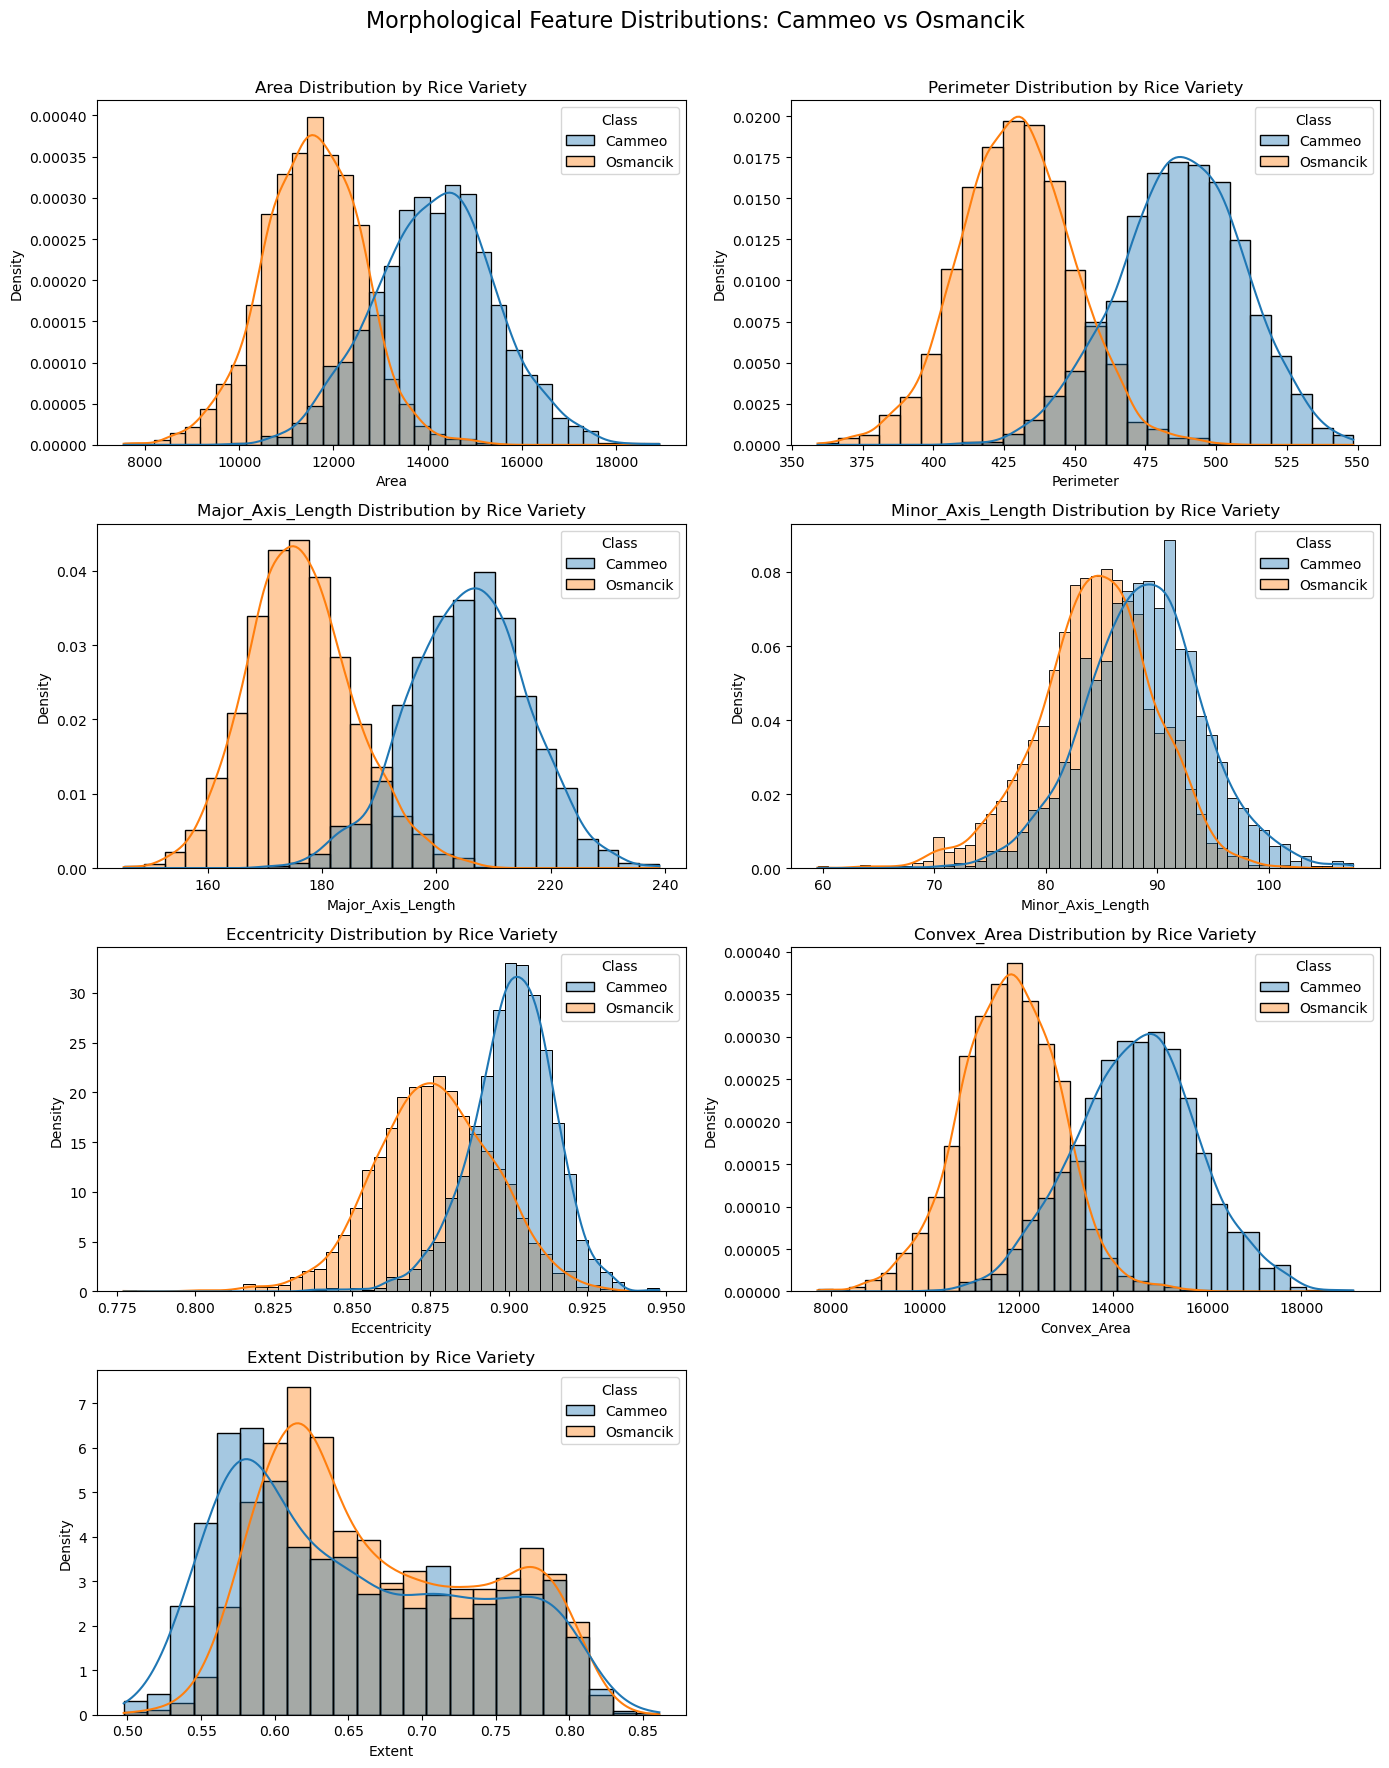

In [15]:
# Distribution Analysis of All Seven Features

import matplotlib.pyplot as plt
import seaborn as sns

features = [
    "Area",
    "Perimeter",
    "Major_Axis_Length",
    "Minor_Axis_Length",
    "Eccentricity",
    "Convex_Area",
    "Extent"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.histplot(
        data=df,
        x=feature,
        hue="Class",
        kde=True,
        stat="density",
        common_norm=False,
        alpha=0.4,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} Distribution by Rice Variety")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Density")

# Remove unused subplot
fig.delaxes(axes[7])

plt.suptitle(
    "Morphological Feature Distributions: Cammeo vs Osmancik",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### Feature Distribution Analysis — Key Findings

The distribution plots compare seven morphological measurements between Cammeo and Osmancik rice grains.

The analysis shows that Area, Perimeter, Major Axis Length and Convex Area have noticeably different distributions across the two varieties. Cammeo grains generally have larger measurements than Osmancik grains.

Eccentricity also demonstrates visible class separation, indicating differences in grain elongation.

In contrast, Minor Axis Length and Extent show substantial overlap between the varieties. These measurements may provide less discriminatory information when considered individually.

Although several features appear promising, all distributions exhibit some overlap. Therefore, no single measurement can guarantee accurate variety classification.

**Business implication:** Morphological measurements provide useful information for developing an automated rice variety classification system. Features showing visible separation may be valuable predictors, but their actual contribution must be established through feature-selection experiments and model validation.

**Limitation:** This analysis is exploratory and does not establish causal relationships or independently validate feature importance.

Feature Correlation Matrix:


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
Area,1.000,0.966,0.903,0.788,0.352,0.999,-0.061
Perimeter,0.966,1.000,0.972,0.630,0.545,0.970,-0.131
Major_Axis_Length,0.903,0.972,1.000,0.452,0.711,0.903,-0.140
Minor_Axis_Length,0.788,0.630,0.452,1.000,-0.292,0.787,0.063
Eccentricity,0.352,0.545,0.711,-0.292,1.000,0.353,-0.199
Convex_Area,0.999,0.970,0.903,0.787,0.353,1.000,-0.066
Extent,-0.061,-0.131,-0.140,0.063,-0.199,-0.066,1.000


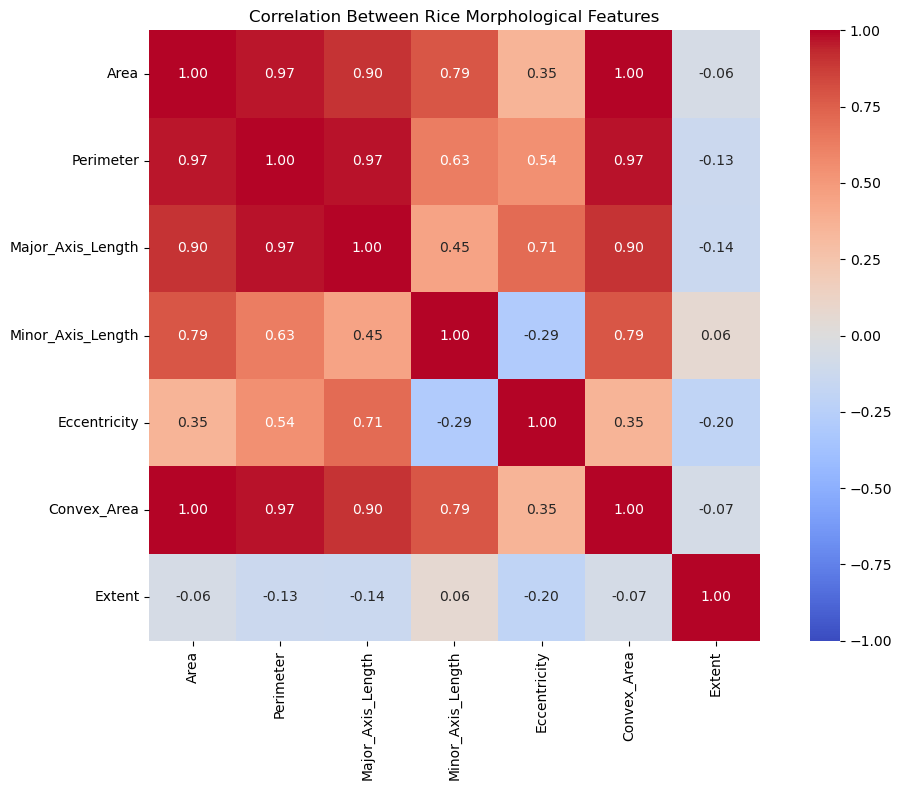

In [16]:
# Correlation Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Select the seven numerical input features
features = df.drop(columns=["Class"])

# Calculate Pearson correlation
correlation_matrix = features.corr(method="pearson")

# Display correlation values
print("Feature Correlation Matrix:")
display(correlation_matrix.round(3))

# Plot correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Between Rice Morphological Features")
plt.tight_layout()
plt.show()

### Correlation Analysis — Key Findings

The Pearson correlation heatmap identifies several strong positive relationships among the seven rice morphological features.

Area and Convex_Area show an almost perfect positive correlation (approximately 1.00), indicating substantial overlap in the information represented by these measurements.

Perimeter and Major_Axis_Length are also strongly correlated (r ≈ 0.97), while Area and Perimeter have a similarly strong relationship (r ≈ 0.97).

Major_Axis_Length and Eccentricity show a positive correlation of approximately 0.71, suggesting a relationship between grain length and elongation.

In contrast, Extent has relatively weak linear correlations with the other morphological measurements.

**Machine Learning Implication:** Highly correlated predictors may introduce redundant information and make individual model coefficients difficult to interpret. Therefore, feature-selection experiments should investigate whether a smaller feature subset can maintain comparable classification performance.

**Business Implication:** The analysis demonstrates that rice grain measurements are interrelated. Understanding these relationships can help guide the development of a simpler and more interpretable variety-classification system.

**Limitation:** Correlation does not imply causation or establish feature importance. Final feature choices must be supported by training-data-based feature selection and model validation.

In [17]:
# Feature Separation Analysis (Cohen's d)

import numpy as np
import pandas as pd

feature_columns = df.drop(columns=["Class"]).columns

cammeo = df[df["Class"] == "Cammeo"]
osmancik = df[df["Class"] == "Osmancik"]

results = []

for feature in feature_columns:

    x1 = cammeo[feature].dropna()
    x2 = osmancik[feature].dropna()

    mean1 = x1.mean()
    mean2 = x2.mean()

    std1 = x1.std(ddof=1)
    std2 = x2.std(ddof=1)

    n1 = len(x1)
    n2 = len(x2)

    pooled_std = np.sqrt(
        ((n1 - 1) * std1**2 + (n2 - 1) * std2**2)
        / (n1 + n2 - 2)
    )

    cohens_d = (
        (mean1 - mean2) / pooled_std
        if pooled_std > 0 else np.nan
    )

    results.append({
        "Feature": feature,
        "Cammeo Mean": mean1,
        "Osmancik Mean": mean2,
        "Cohen's d": cohens_d,
        "Absolute d": abs(cohens_d)
    })

separation_df = pd.DataFrame(results)

separation_df = separation_df.sort_values(
    by="Absolute d",
    ascending=False
)

display(separation_df.round(3))

,Feature,Cammeo Mean,Osmancik Mean,Cohen's d,Absolute d
2,Major_Axis_Length,205.479,176.288,2.982,2.982
1,Perimeter,487.439,429.416,2.757,2.757
5,Convex_Area,14494.427,11799.586,2.294,2.294
0,Area,14162.892,11549.783,2.266,2.266
4,Eccentricity,0.901,0.876,1.472,1.472
3,Minor_Axis_Length,88.768,84.479,0.806,0.806
6,Extent,0.651,0.670,-0.240,0.240


### Feature Separation Analysis — Interpretation

To quantify differences between Cammeo and Osmancik rice varieties, Cohen's d was calculated for all seven numerical morphological features.

The results show that **Major_Axis_Length (d = 2.982)** has the largest standardized mean difference, followed by **Perimeter (d = 2.757)**, Convex_Area (d = 2.294), and Area (d = 2.266).

These findings suggest that grain length, boundary length, and grain size provide substantial separation between the two varieties in the dataset.

Eccentricity also shows a large standardized difference (d = 1.472), while Minor_Axis_Length has a smaller but still substantial difference (d = 0.806).

Extent has the smallest absolute standardized mean difference (|d| = 0.240), indicating relatively similar class means compared with its variability.

The findings are consistent with the earlier feature-distribution plots, which showed noticeable differences in Major_Axis_Length and Perimeter.

**Machine Learning Implication:** Major_Axis_Length and Perimeter are promising candidates for classification. However, Cohen's d measures univariate mean separation rather than multivariable predictive importance. Their final selection must be justified through training-data-based feature selection and cross-validation.

**Business Implication:** Differences in measurable grain geometry support the feasibility of a rice variety verification system that could assist agricultural quality-control personnel.

**Limitation:** The analysis is exploratory, and large standardized mean differences do not guarantee perfect classification because individual grain measurements can overlap.

## Final Findings and Business Interpretation

The Rice Cammeo and Osmancik dataset contains 3,810 observations, seven numerical morphological features and one categorical target variable. Each observation represents an individual rice grain.

The dataset contains 1,630 Cammeo grains (42.78%) and 2,180 Osmancik grains (57.22%), indicating moderate class imbalance.

### Key Findings

1. **Morphological differences:** Cammeo grains generally have larger Area, Perimeter, Major Axis Length and Convex Area measurements than Osmancik grains.

2. **Feature separation:** Major_Axis_Length (Cohen's d = 2.982) and Perimeter (d = 2.757) show the largest standardized mean differences between the two rice varieties.

3. **Feature correlation:** Area and Convex_Area are almost perfectly correlated, while Perimeter and Major_Axis_Length have a strong positive correlation of approximately 0.97. This suggests that some measurements contain overlapping information.

4. **Feature overlap:** Despite differences in class averages, the feature-distribution plots reveal overlapping measurements. Therefore, no individual feature guarantees accurate variety classification.

### Implications for Machine Learning

The exploratory findings support the use of supervised binary classification to distinguish Cammeo and Osmancik rice grains.

Major_Axis_Length and Perimeter appear promising based on their standardized mean differences. However, the final feature subset must be selected and validated using training data rather than relying exclusively on exploratory statistics.

The moderate class imbalance supports using stratified sampling and multiple evaluation metrics rather than accuracy alone.

### Business Recommendation

The results indicate that measurable grain characteristics could support an automated rice variety verification system.

Such a system could assist agricultural quality-control personnel by comparing a predicted variety with the expected variety and flagging disagreements for further inspection.

The system should be treated as decision support, not as a replacement for laboratory testing or final quality-control procedures.

### Limitations

The analysis uses morphological measurements from the provided dataset and does not establish performance on new rice batches, different imaging equipment, or other rice varieties.

The findings are exploratory and should be followed by appropriate model validation and external testing before operational deployment.